In [20]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [5]:
sp500 = yf.download(
    "^GSPC",
    start="2016-05-23",
    end="2026-05-23",
    auto_adjust=False
)["Close"]



print("First five observations:")
display(sp500.head())

print("Last five observations:")
display(sp500.tail())

N = len(sp500)

print("Total number of observations:", N)

[*********************100%***********************]  1 of 1 completed

First five observations:


Ticker,^GSPC
Date,
2016-05-23,2048.040039
2016-05-24,2076.060059
2016-05-25,2090.540039
2016-05-26,2090.100098
2016-05-27,2099.060059


Last five observations:


Ticker,^GSPC
Date,
2026-05-18,7403.049805
2026-05-19,7353.609863
2026-05-20,7432.970215
2026-05-21,7445.720215
2026-05-22,7473.470215


Total number of observations: 2515


# 2

In [12]:
def full_loss(x):
    return 1 - np.exp(x)

In [13]:
def empirical_var(losses, alpha):
    sorted_losses = np.sort(losses)
    n = len(sorted_losses)

    index = int(np.ceil(n * alpha)) - 1

    return sorted_losses[index]

In [18]:
alpha = 0.95
M = 1010

log_returns = np.log(sp500 / sp500.shift(1)).dropna()
returns = log_returns.to_numpy().flatten()

var_empirical = []
realized_losses = []
exceedances = []
evaluation_dates = []

for i in range(M, len(returns)):

    window_returns = returns[i - M:i]
    window_losses = full_loss(window_returns)
    var_t = empirical_var(window_losses, alpha)
    realized_loss = full_loss(returns[i])
    exceedance = int(realized_loss > var_t)

    var_empirical.append(var_t)
    realized_losses.append(realized_loss)
    exceedances.append(exceedance)
    evaluation_dates.append(log_returns.index[i])

backtest_empirical = pd.DataFrame({
    "VaR": var_empirical,
    "Realized Loss": realized_losses,
    "Exceedance": exceedances
}, index=evaluation_dates)

print("Empirical Backtest Head:")
display(backtest_empirical.head())
print("Evaluation periods:", len(backtest_empirical))
print("Number of exceedances:", backtest_empirical["Exceedance"].sum())
print(f"Percentage of exceedances: {backtest_empirical["Exceedance"].sum()/len(backtest_empirical)*100:.4f}%" )

Empirical Backtest Head:


,VaR,Realized Loss,Exceedance
2020-05-29,0.017327,-0.004812,0
2020-06-01,0.017327,-0.003751,0
2020-06-02,0.017327,-0.008211,0
2020-06-03,0.017327,-0.013649,0
2020-06-04,0.017327,0.003369,0


Evaluation periods: 1504
Number of exceedances: 55
Percentage of exceedances: 3.6569%


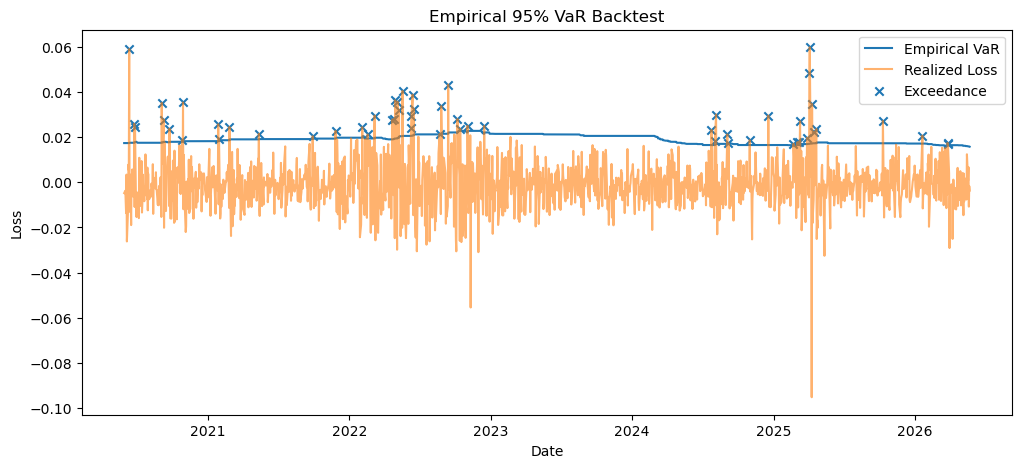

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    backtest_empirical.index,
    backtest_empirical["VaR"], 
    label="Empirical VaR"
)

plt.plot(
    backtest_empirical.index,
    backtest_empirical["Realized Loss"],
    label="Realized Loss",
    alpha=0.6
)

plt.scatter(
    backtest_empirical.index[backtest_empirical["Exceedance"] == 1],
    backtest_empirical.loc[
        backtest_empirical["Exceedance"] == 1,
        "Realized Loss"
    ],
    label="Exceedance",
    marker="x"
)

plt.xlabel("Date")
plt.ylabel("Loss")
plt.title("Empirical 95% VaR Backtest")
plt.legend()
plt.show()

# 3

In [21]:
lambda_ewma = 0.97
theta_ewma = 0.97

var_ewma_series = []
realized_losses_ewma = []
exceedances_ewma = []
evaluation_dates_ewma = []

initial_returns = returns[:M]
mu_ewma = np.mean(initial_returns)
var_ewma = np.var(initial_returns, ddof=1)


for i in range(M, len(returns)):

    sigma_ewma = np.sqrt(var_ewma)
    var_t = 1 - np.exp(
        mu_ewma
        + sigma_ewma * norm.ppf(1 - alpha)
    )
    realized_loss = full_loss(returns[i])
    exceedance = int(realized_loss > var_t)
    var_ewma_series.append(var_t)
    realized_losses_ewma.append(realized_loss)
    exceedances_ewma.append(exceedance)
    evaluation_dates_ewma.append(log_returns.index[i])
    deviation = returns[i] - mu_ewma

    var_ewma = (
        theta_ewma * var_ewma
        + (1 - theta_ewma) * deviation**2
    )

    mu_ewma = (
        lambda_ewma * mu_ewma
        + (1 - lambda_ewma) * returns[i]
    )

backtest_ewma = pd.DataFrame({
    "VaR": var_ewma_series,
    "Realized Loss": realized_losses_ewma,
    "Exceedance": exceedances_ewma
}, index=evaluation_dates_ewma)

print("Backtest EWMA: ")
display(backtest_ewma.head())
print("Evaluation periods:", len(backtest_ewma))
print("Number of exceedances:",
      backtest_ewma["Exceedance"].sum())

print(
    "Percentage of exceedances:",
    f'{backtest_ewma["Exceedance"].mean() * 100:.4f}%'
)

Backtest EWMA: 


,VaR,Realized Loss,Exceedance
2020-05-29,0.019830,-0.004812,0
2020-06-01,0.019436,-0.003751,0
2020-06-02,0.019064,-0.008211,0
2020-06-03,0.018662,-0.013649,0
2020-06-04,0.018325,0.003369,0


Evaluation periods: 1504
Number of exceedances: 94
Percentage of exceedances: 6.2500%


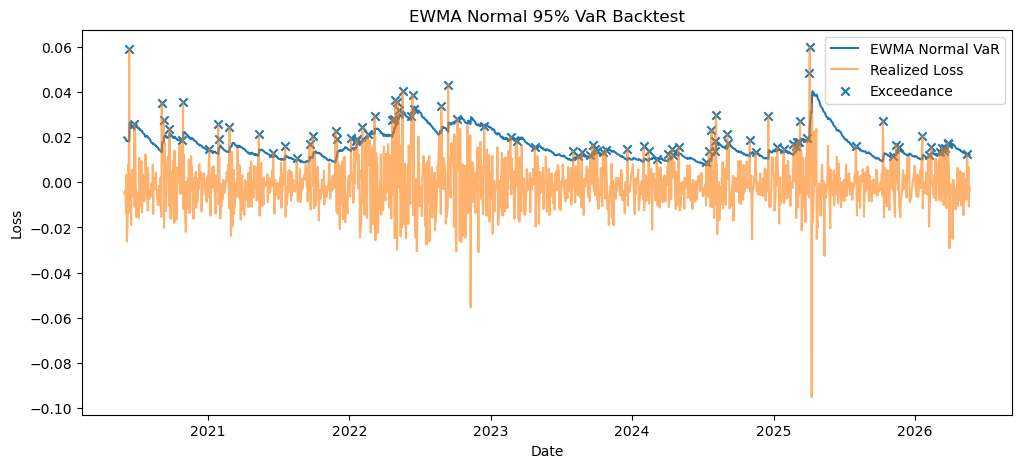

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    backtest_ewma.index,
    backtest_ewma["VaR"],
    label="EWMA Normal VaR"
)

plt.plot(
    backtest_ewma.index,
    backtest_ewma["Realized Loss"],
    label="Realized Loss",
    alpha=0.6
)

plt.scatter(
    backtest_ewma.index[backtest_ewma["Exceedance"] == 1],
    backtest_ewma.loc[
        backtest_ewma["Exceedance"] == 1,
        "Realized Loss"
    ],
    marker="x",
    label="Exceedance"
)

plt.xlabel("Date")
plt.ylabel("Loss")
plt.title("EWMA Normal 95% VaR Backtest")
plt.legend()
plt.show()